In [25]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import Opgave.mymlr as mlr
from scipy.stats import chi2, f
df = pd.read_csv("Opgave/data/cars.csv")

Opgave 1A

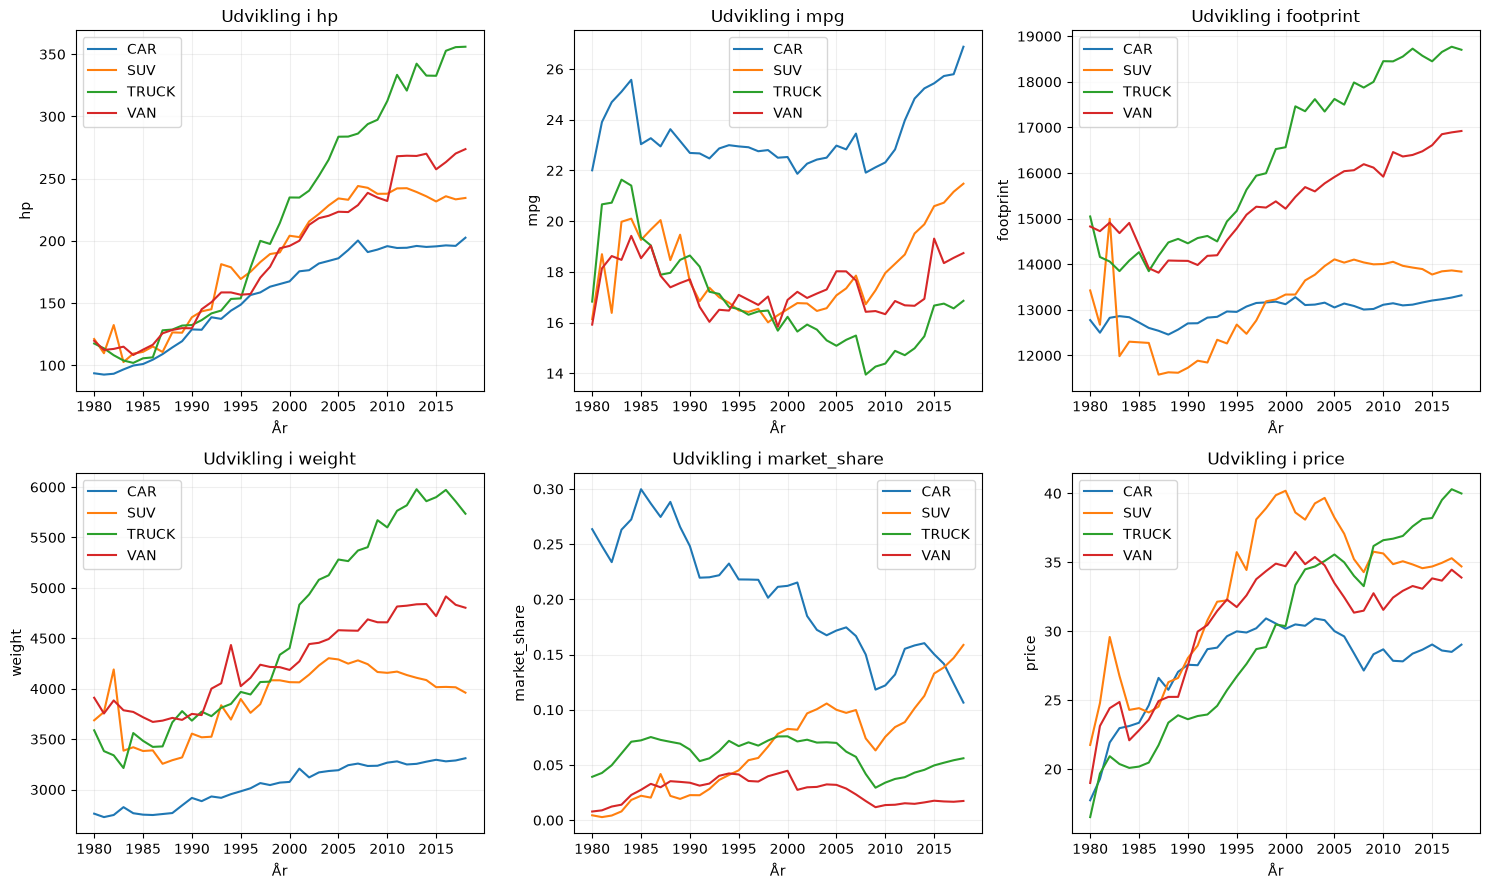

In [26]:
attributes = ["hp", "mpg", "footprint", "weight", "market_share", "price"]
types = ["car", "suv", "truck", "van"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, var in zip(axes, attributes):
    for typ in types:
        if var == "market_share":
            grouped = (
                df[df[typ] == 1]
                .groupby("year")["market_share"]
                .sum()
            )
        else:
            grouped = (
                df[df[typ] == 1]
                .groupby("year")
                .apply(
                    lambda x: np.average(x[var], weights=x["sales"]),
                    include_groups=False
                )
            )

        ax.plot(grouped.index, grouped.values, label=typ.upper())

    ax.set_title(f"Udvikling i {var}")
    ax.set_xlabel("År")
    ax.set_ylabel(var)
    ax.legend()
    ax.grid(True, alpha=0.2)



plt.tight_layout()
plt.show()




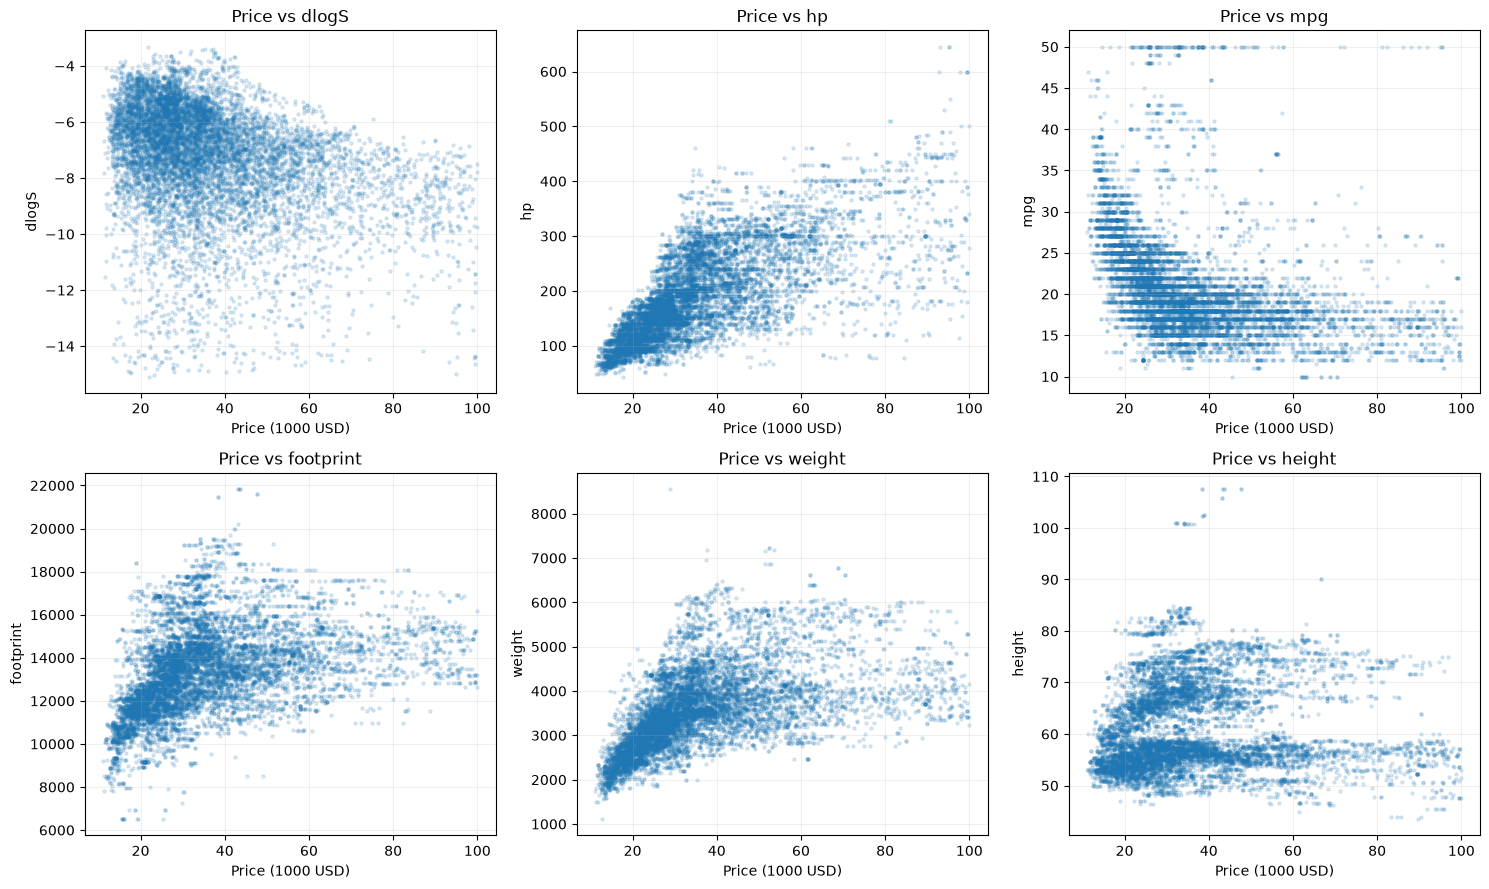

In [27]:
variables = ["dlogS", "hp", "mpg", "footprint", "weight","height"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, var in zip(axes, variables):
    ax.scatter(df["price"], df[var], alpha=0.15, s=5)

    ax.set_xlabel("Price (1000 USD)")
    ax.set_ylabel(var)
    ax.set_title(f"Price vs {var}")
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


Opgave 1B

Specifikation 1

In [28]:
df["const"] = 1
y = (df["dlogS"])
X1 = df[["const","price"]]
specifikation1 = mlr.ols(y, X1)
mlr.output(specifikation1)


OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9692 (Residual), 2 (Model)
R-squared: 0.1062
TSS: 37300.6952, RSS: 33339.4749, ESS: 3961.2203
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                       -5.9072         0.0439   -134.5673      0.0000   [ -5.9933, -5.8212 ]
price                       -0.0373         0.0011    -33.9345      0.0000   [ -0.0395, -0.0352 ]


Specifikation 2

In [29]:
x = ["const","hp", "mpg", "height","footprint","weight","number_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]

X2 = df[x + ["price"]]
y = (df["dlogS"])
specifikation2 = mlr.ols(y, X2)
mlr.output(specifikation2)

OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9679 (Residual), 15 (Model)
R-squared: 0.3001
TSS: 37300.6952, RSS: 26108.3630, ESS: 11192.3322
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                       -5.4138         0.2908    -18.6167      0.0000   [ -5.9838, -4.8438 ]
hp                          -0.0038         0.0004    -10.1846      0.0000   [ -0.0045, -0.0031 ]
mpg                         -0.0427         0.0037    -11.6670      0.0000   [ -0.0498, -0.0355 ]
height                      -0.0237         0.0048     -4.9020      0.0000   [ -0.0331, -0.0142 ]
footprint                    0.0004         0.0000     19.1176      0.0000   [  0.0003, 0.0004  ]
weight                      -0.0007         0.0001    -10.9435      0.0000   [ -0.0008, -0.0006 ]
number_trims     

Specifikation 3

Tilføj years

In [30]:
year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)
years = list(year_dummies.columns)
df = df.loc[:, ~df.columns.duplicated()].copy()

Lav specifikation 3

In [31]:
x = ["const","hp", "mpg", "height","footprint","weight","number_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]

X3 = df[x + ["price"] + years]
y = (df["dlogS"])
specifikation3 = mlr.ols(y, X3)
mlr.output(specifikation3)

OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9641 (Residual), 53 (Model)
R-squared: 0.3410
TSS: 37300.6952, RSS: 24580.4692, ESS: 12720.2260
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                       -6.8066         0.3177    -21.4231      0.0000   [ -7.4294, -6.1838 ]
hp                           0.0024         0.0005      4.8783      0.0000   [  0.0014, 0.0034  ]
mpg                         -0.0115         0.0042     -2.7218      0.0065   [ -0.0197, -0.0032 ]
height                      -0.0154         0.0047     -3.2439      0.0012   [ -0.0247, -0.0061 ]
footprint                    0.0003         0.0000     16.6201      0.0000   [  0.0003, 0.0003  ]
weight                      -0.0006         0.0001     -9.0157      0.0000   [ -0.0007, -0.0005 ]
number_trims     

Specifikation 4

Opret log-udgaver af de udvalgte variable

In [32]:
vars = ["hp", "mpg", "height", "footprint", "weight", "number_trims"]

for var in vars:
    df[f"log{var}"] = np.log(df[f"{var}"])

Kør specifikation 4

In [33]:
x = ["const","loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]

X4 = df[x + ["price"] + years]
y = (df["dlogS"])
specifikation4 = mlr.ols(y, X4)
mlr.output(specifikation4)

OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9641 (Residual), 53 (Model)
R-squared: 0.5065
TSS: 37300.6952, RSS: 18407.0415, ESS: 18893.6537
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                      -25.4344         1.6540    -15.3772      0.0000   [-28.6767, -22.1922]
loghp                        0.4285         0.0994      4.3118      0.0000   [  0.2337, 0.6233  ]
logmpg                       0.3280         0.1079      3.0395      0.0024   [  0.1165, 0.5396  ]
logheight                   -1.2168         0.2632     -4.6236      0.0000   [ -1.7327, -0.7009 ]
logfootprint                 2.9136         0.2203     13.2249      0.0000   [  2.4817, 3.3454  ]
logweight                   -0.8093         0.2115     -3.8262      0.0001   [ -1.2239, -0.3947 ]
lognumber_trims  

1C

Få residualer og regresser de kvadrarede residualer mod de forklarende variable fra specifikation4 

In [34]:
u_hat = specifikation4["u_hat"]
df["uhat2"] = u_hat**2
bp = mlr.ols(df["uhat2"],X4)
#mlr.output(bp)

Kør en F-test for at undersøge heteroskedasticitet

In [35]:
#Find den kritiske F-værdi, ved 95% konfidens interval, 52 parametre (restriktioner), og 9694 observationer fra trukket de 52 restriktioner samt konstanten, giver 9641 frihedsgrader
F_crit = f.ppf(1 - 0.05, 52, 9694 - 53)
print(F_crit)

#urestrikteret model, regresser kvadrarede residaler på samme specifikation
specifikation4URestrikteret = mlr.ols(df["uhat2"],X4)

#restrikteret model, regresser kvadrarede residiauler mod antagelse om at alle parametre udover constanten er 0 
specifikation4Restrikteret = mlr.ols(df["uhat2"], df[["const"]])

mlr.Ftest(specifikation4URestrikteret,specifikation4Restrikteret)

1.3443066826101033


(26.935138777330668, np.float64(0.0))

In [36]:
#Lav de robuste modeller
specifikation1R = mlr.ols(y,X1, robust=True)
specifikation2R = mlr.ols(y,X2, robust=True)
specifikation3R = mlr.ols(y,X3, robust=True)
specifikation4R = mlr.ols(y,X4, robust=True)

In [37]:
mlr.output(specifikation1R)

OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9692 (Residual), 2 (Model)
R-squared: 0.1062
TSS: 37300.6952, RSS: 33339.4749, ESS: 3961.2203
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                       -5.9072         0.0426   -138.6341      0.0000   [ -5.9907, -5.8237 ]
price                       -0.0373         0.0010    -35.7560      0.0000   [ -0.0394, -0.0353 ]


In [38]:
mlr.output(specifikation2R)

OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9679 (Residual), 15 (Model)
R-squared: 0.3001
TSS: 37300.6952, RSS: 26108.3630, ESS: 11192.3322
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                       -5.4138         0.2915    -18.5749      0.0000   [ -5.9851, -4.8425 ]
hp                          -0.0038         0.0004    -10.2779      0.0000   [ -0.0045, -0.0031 ]
mpg                         -0.0427         0.0037    -11.4069      0.0000   [ -0.0500, -0.0353 ]
height                      -0.0237         0.0051     -4.6825      0.0000   [ -0.0336, -0.0138 ]
footprint                    0.0004         0.0000     18.2112      0.0000   [  0.0003, 0.0004  ]
weight                      -0.0007         0.0001    -10.3623      0.0000   [ -0.0008, -0.0006 ]
number_trims     

In [39]:
mlr.output(specifikation3R)

OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9641 (Residual), 53 (Model)
R-squared: 0.3410
TSS: 37300.6952, RSS: 24580.4692, ESS: 12720.2260
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                       -6.8066         0.3045    -22.3521      0.0000   [ -7.4035, -6.2097 ]
hp                           0.0024         0.0005      4.6715      0.0000   [  0.0014, 0.0034  ]
mpg                         -0.0115         0.0044     -2.6128      0.0090   [ -0.0201, -0.0029 ]
height                      -0.0154         0.0050     -3.1048      0.0019   [ -0.0251, -0.0057 ]
footprint                    0.0003         0.0000     16.1159      0.0000   [  0.0003, 0.0003  ]
weight                      -0.0006         0.0001     -8.7621      0.0000   [ -0.0007, -0.0004 ]
number_trims     

In [40]:
mlr.output(specifikation4R)

OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9641 (Residual), 53 (Model)
R-squared: 0.5065
TSS: 37300.6952, RSS: 18407.0415, ESS: 18893.6537
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                      -25.4344         1.7798    -14.2903      0.0000   [-28.9233, -21.9456]
loghp                        0.4285         0.1049      4.0834      0.0000   [  0.2228, 0.6342  ]
logmpg                       0.3280         0.1218      2.6925      0.0071   [  0.0892, 0.5668  ]
logheight                   -1.2168         0.2824     -4.3080      0.0000   [ -1.7705, -0.6631 ]
logfootprint                 2.9136         0.2287     12.7385      0.0000   [  2.4652, 3.3619  ]
logweight                   -0.8093         0.2175     -3.7215      0.0002   [ -1.2356, -0.3830 ]
lognumber_trims  

Opgave 2

Lav make-dummier, ændre nogle navne for at gøre livet nememre senere

In [41]:
df["make"] = df["make"].replace("alfa romeo", "alfaRomeo")
df["make"] = df["make"].replace("land rover", "landRover")
df["make"] = df["make"].replace("sterling cars", "sterlingCars")
df["make"] = df["make"].replace("mercedes-benz", "mercedesBenz")
df["make"] = df["make"].replace("austin-rover", "austinRover")
make_dummies = pd.get_dummies(df['make'], prefix='make', drop_first=True, dtype=int)
df = pd.concat([df, make_dummies], axis=1)
xi_m = list(make_dummies.columns)
df = df.loc[:, ~df.columns.duplicated()].copy()


Make-dummy model

In [42]:
x = ["const","loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]

X5 = df[x + ["price"] + years + xi_m]
y = (df["dlogS"])
model2A1 = mlr.ols(y,X5)    
mlr.output(model2A1)


OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9580 (Residual), 114 (Model)
R-squared: 0.5889
TSS: 37300.6952, RSS: 15333.5079, ESS: 21967.1873
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                      -15.1108         1.7284     -8.7425      0.0000   [-18.4989, -11.7227]
loghp                        0.3750         0.0950      3.9478      0.0001   [  0.1888, 0.5611  ]
logmpg                      -0.1240         0.1045     -1.1872      0.2352   [ -0.3288, 0.0808  ]
logheight                   -0.8707         0.2550     -3.4147      0.0006   [ -1.3706, -0.3709 ]
logfootprint                 2.0209         0.2279      8.8695      0.0000   [  1.5743, 2.4676  ]
logweight                   -0.9774         0.2024     -4.8298      0.0000   [ -1.3741, -0.5807 ]
lognumber_trims 

Within-transformation

Lav within transformation

In [43]:
x = ["const","loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]
XingenWithin = df[x + ["price"] + years]
df_within = df.copy()
vars_to_transform = XingenWithin  # List the names of the variables to transform
for var in vars_to_transform:
    make_mean = df_within.groupby('make')[var].transform('mean')
    df_within[var] = df[var] - make_mean

Kør regressionen, husk at fjerne const da den er 0 nu

In [44]:
X6 = df_within[XingenWithin.columns.drop("const")]
y6 = df["dlogS"] - df.groupby("make")["dlogS"].transform("mean")

model2A2 = mlr.ols(y6, X6)
mlr.output(model2A2)

OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9642 (Residual), 52 (Model)
R-squared: 0.4959
TSS: 30415.6145, RSS: 15333.5079, ESS: 15082.1066
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
loghp                        0.3750         0.0947      3.9606      0.0001   [  0.1894, 0.5605  ]
logmpg                      -0.1240         0.1041     -1.1910      0.2337   [ -0.3282, 0.0801  ]
logheight                   -0.8707         0.2542     -3.4258      0.0006   [ -1.3689, -0.3725 ]
logfootprint                 2.0209         0.2271      8.8981      0.0000   [  1.5757, 2.4661  ]
logweight                   -0.9774         0.2017     -4.8454      0.0000   [ -1.3728, -0.5820 ]
lognumber_trims              1.1894         0.0173     68.6062      0.0000   [  1.1554, 1.2234  ]
releaseYear      

2C

First stage regression

In [50]:
x = ["loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]
X7 = df[x + years + xi_m]
y = df["dlogS"]
firstStage = mlr.first_stage(y,X7,df["price"],df["RXR"], quiet=False)

First Stage for price, Dependent Variable: ['price']
Number of Observations: 9694
Degrees of Freedom: 9581 (Residual), 113 (Model)
R-squared: 0.8072
TSS: 2843143.1020, RSS: 548186.2537, ESS: 2294956.8483
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
RXR                          3.3252         0.5243      6.3423      0.0000   [  2.2975, 4.3529  ]
loghp                       15.6585         0.5380     29.1048      0.0000   [ 14.6039, 16.7131 ]
logmpg                      -0.3693         0.5554     -0.6650      0.5061   [ -1.4580, 0.7194  ]
logheight                  -27.6651         1.3919    -19.8756      0.0000   [-30.3936, -24.9367]
logfootprint               -26.7574         0.9704    -27.5736      0.0000   [-28.6596, -24.8553]
logweight                   40.1555         1.1145     36.0315      0.0000   [ 37.9710, 42.3401 ]
lognumber_tr

In [60]:
df["firstStageUhat"]=firstStage[0]["u_hat"]

XEhat = pd.concat([X7, df["price"], df['firstStageUhat']], axis=1)
m_exogeneity_test = mlr.ols(y=y, X=XEhat, robust=True, quiet=False, title="Exogeneity Test Results")

Exogeneity Test Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9580 (Residual), 114 (Model)
R-squared: 0.5879
TSS: 37300.6952, RSS: 15372.3578, ESS: 21928.3374
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
loghp                        3.2551         0.4471      7.2811      0.0000   [  2.3788, 4.1315  ]
logmpg                      -0.6080         0.0975     -6.2376      0.0000   [ -0.7991, -0.4169 ]
logheight                   -6.9720         0.8128     -8.5781      0.0000   [ -8.5651, -5.3788 ]
logfootprint                -4.3789         0.7676     -5.7043      0.0000   [ -5.8837, -2.8742 ]
logweight                    7.0068         1.1415      6.1384      0.0000   [  4.7693, 9.2443  ]
lognumber_trims              0.9676         0.0389     24.8803      0.0000   [  0.8914, 1.0439  ]
releaseYear    

strukturelle efterspørgselsligning ved 2SLS

In [ ]:
x = ["const","loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]
X8 = df[x + years + xi_m]
y = df["dlogS"]

strukturelEfterspørgsel = mlr.tsls(y,X8,df["price"],df["RXR"])
mlr.output(strukturelEfterspørgsel)


OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9580 (Residual), 114 (Model)
R-squared: 0.3269
TSS: 37300.6952, RSS: 25106.1190, ESS: 12194.5762
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                      -40.8562         5.5889     -7.3102      0.0000   [-51.8117, -29.9008]
loghp                        2.6639         0.4722      5.6410      0.0000   [  1.7382, 3.5895  ]
logmpg                       0.5428         0.1885      2.8789      0.0040   [  0.1732, 0.9123  ]
logheight                   -3.1315         0.5564     -5.6279      0.0000   [ -4.2222, -2.0408 ]
logfootprint                 0.8242         0.3767      2.1878      0.0287   [  0.0857, 1.5627  ]
logweight                    3.7059         0.9689      3.8248      0.0001   [  1.8066, 5.6051  ]
lognumber_trims 

Opgave 3

GH alene

In [48]:
x = ["const","loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]
X8 = df[x + years + xi_m]
y = df["dlogS"]
GH = ["gh_log_height", "gh_log_footprint", "gh_log_hp", "gh_log_mpg", "gh_log_weight"]


GHInstrumenterAlene = mlr.tsls(y,X8,df["price"],df[GH])
mlr.output(GHInstrumenterAlene)

#Vi antager homoskedasticitet og laver Sargan-test
X9 = df[x + years + xi_m + GH]
df["uhatGHAlene"] = GHInstrumenterAlene["u_hat"].flatten()
sargan = mlr.ols(df["uhatGHAlene"],X9)
J_stat = sargan["R_squared"] * sargan["n"]

g = 5  # Antal ekskluderede instrumenter
l = 1  # Antal endogene variable
p_value = chi2.sf(J_stat, df=g-l)
print(f"Sargan-teststatistik, J ~ Chi2({g-l}): {J_stat:.4f}")
print(f"P-værdi: {p_value:.4f}")



OLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9580 (Residual), 114 (Model)
R-squared: 0.5858
TSS: 37300.6952, RSS: 15448.3332, ESS: 21852.3620
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                      -12.3201         1.8729     -6.5781      0.0000   [-15.9914, -8.6488 ]
loghp                        0.1268         0.1141      1.1115      0.2664   [ -0.0969, 0.3505  ]
logmpg                      -0.1963         0.1064     -1.8442      0.0652   [ -0.4050, 0.0123  ]
logheight                   -0.6257         0.2633     -2.3759      0.0175   [ -1.1419, -0.1095 ]
logfootprint                 2.1507         0.2310      9.3084      0.0000   [  1.6978, 2.6036  ]
logweight                   -1.4850         0.2403     -6.1805      0.0000   [ -1.9560, -1.0140 ]
lognumber_trims 

GH og RXR

In [ ]:
x = ["const","loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]
X8 = df[x + years + xi_m]
y = df["dlogS"]
GHRXR = ["gh_log_height", "gh_log_footprint", "gh_log_hp", "gh_log_mpg", "gh_log_weight", "RXR"]

GHInstrumenterRXR = mlr.tsls(y,X8,df["price"],df[GHRXR], quiet=False)
mlr.output(GHInstrumenterRXR)

#Vi antager homoskedasticitet og laver Sargan-test
X9 = df[x + years + xi_m + GHRXR]
df["uhatGHRXR"] = GHInstrumenterRXR["u_hat"].flatten()
sargan = mlr.ols(df["uhatGHRXR"],X9)
J_stat = sargan["R_squared"] * sargan["n"]

g = 6  # Antal ekskluderede instrumenter
l = 1  # Antal endogene variable
p_value = chi2.sf(J_stat, df=g-l)
print(f"Sargan-teststatistik, J ~ Chi2({g-l}): {J_stat:.4f}")
print(f"P-værdi: {p_value:.4f}")


2SLS Regression Results, Dependent Variable: ['dlogS']
Number of Observations: 9694
Degrees of Freedom: 9580 (Residual), 114 (Model)
R-squared: 0.5879
TSS: 37300.6952, RSS: 15372.9645, ESS: 21927.7307
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                      -13.4749         1.8610     -7.2408      0.0000   [-17.1229, -9.8270 ]
loghp                        0.2295         0.1129      2.0331      0.0421   [  0.0082, 0.4508  ]
logmpg                      -0.1664         0.1061     -1.5683      0.1168   [ -0.3744, 0.0416  ]
logheight                   -0.7271         0.2623     -2.7720      0.0056   [ -1.2412, -0.2129 ]
logfootprint                 2.0970         0.2304      9.1034      0.0000   [  1.6454, 2.5485  ]
logweight                   -1.2750         0.2378     -5.3617      0.0000   [ -1.7411, -0.8088 ]
lognumber_trims

3B

             mc_IV  egenpriselasticitet_IV    markup_IV
count  9694.000000             9694.000000  9694.000000
mean     30.136069               -6.099407     0.198549
std      17.129868                2.902347     0.084395
min       5.216138              -16.933235     0.059055
25%      18.171184               -7.344564     0.136155
50%      25.907695               -5.385234     0.185693
75%      37.495112               -4.074560     0.245425
max      94.081646               -1.879820     0.531966


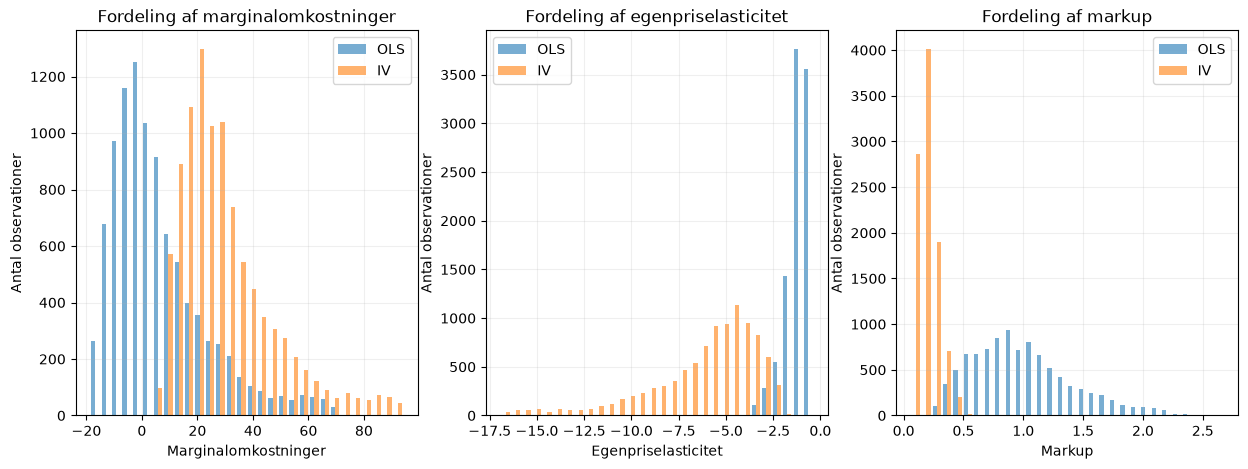

In [ ]:
alphaHatOLS = -0.0337
alphaHatIV_RXR = -0.1694

for name, alpha in [("OLS", alphaHatOLS), ("IV", alphaHatIV_RXR)]:
    df[f"mc_{name}"] = df["price"] - 1 / (-alpha * (1 - df["market_share"]))
    df[f"egenpriselasticitet_{name}"] = alpha * df["price"] * (1 - df["market_share"])
    df[f"markup_{name}"] = (df["price"] - df[f"mc_{name}"]) / df["price"]


variables = [
    ("mc_OLS", "mc_IV"),
    ("egenpriselasticitet_OLS", "egenpriselasticitet_IV"),
    ("markup_OLS", "markup_IV")
]

titles = ["Marginalomkostninger", "Egenpriselasticitet", "Markup"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, var, title in zip(axes, variables, titles):

    ax.hist(
        [df[var[0]], df[var[1]]],
        bins=30,
        alpha=0.6,
        label=["OLS", "IV"]
    )

    ax.set_xlabel(title)
    ax.set_ylabel("Antal observationer")
    ax.set_title(f"Fordeling af {title.lower()}")
    ax.legend()
    ax.grid(True, alpha=0.2)

columnsToDesribe = ["mc_IV","egenpriselasticitet_IV","markup_IV"]
print(df[columnsToDesribe].describe())

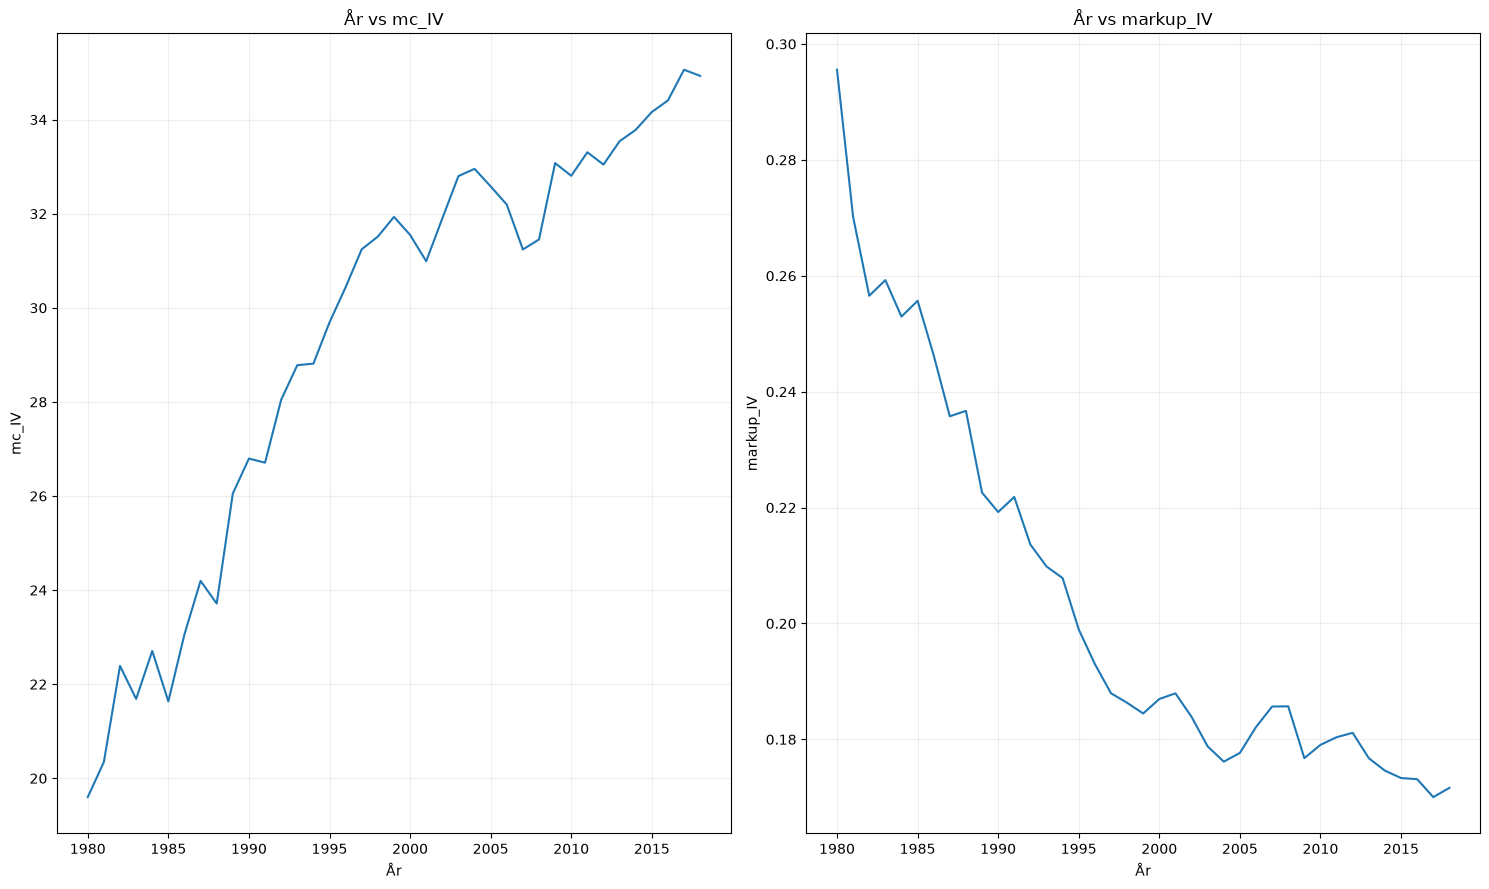

In [ ]:
variables = ["mc_IV", "markup_IV"]

fig, axes = plt.subplots(1, 2, figsize=(15, 9))
axes = axes.flatten()

for ax, var in zip(axes, variables):
    toPlot = df.groupby("year")[var].mean()
    ax.plot(toPlot.index, toPlot.values)

    ax.set_xlabel("År")
    ax.set_ylabel(var)
    ax.set_title(f"År vs {var}")
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()



<Axes: xlabel='year'>

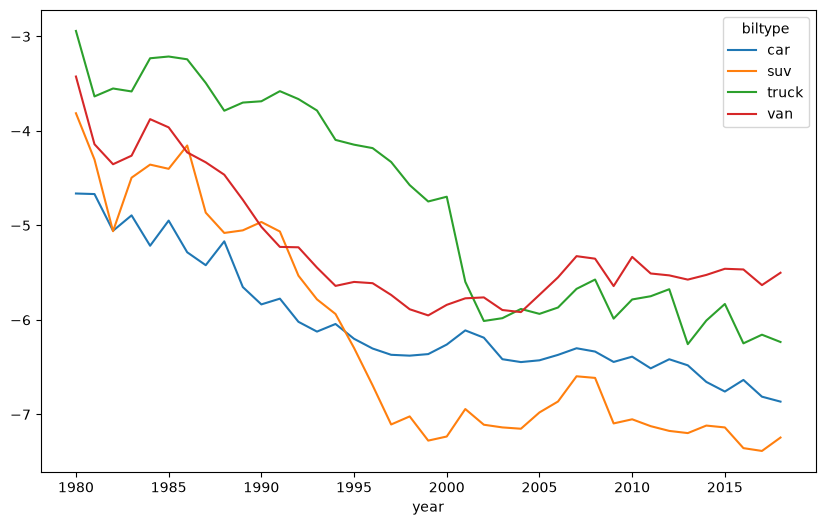

In [ ]:
df["biltype"] = "car"

for biltype in ["suv", "truck", "van"]:
    df.loc[df[biltype] == 1, "biltype"] = biltype

group = (df.groupby(["year", "biltype"])["egenpriselasticitet_IV"].mean().unstack())
group.plot(figsize=(10, 6))

OLS Regression Results, Dependent Variable: ['logmc']
Number of Observations: 9694
Degrees of Freedom: 9580 (Residual), 114 (Model)
R-squared: 0.8793
TSS: 2874.6517, RSS: 346.9819, ESS: 2527.6698
Variable                Coefficient     Std. Error           t       P>|t|    95% Conf. Interval
--------------------------------------------------------------------------------------------------
const                       -6.1841         0.2561    -24.1490      0.0000   [ -6.6861, -5.6821 ]
loghp                        0.4663         0.0136     34.2773      0.0000   [  0.4396, 0.4929  ]
logmpg                       0.1115         0.0157      7.1171      0.0000   [  0.0808, 0.1423  ]
logheight                   -0.7765         0.0382    -20.3488      0.0000   [ -0.8513, -0.7017 ]
logfootprint                -0.1368         0.0342     -3.9965      0.0001   [ -0.2039, -0.0697 ]
logweight                    1.3618         0.0291     46.8158      0.0000   [  1.3048, 1.4189  ]
lognumber_trims     

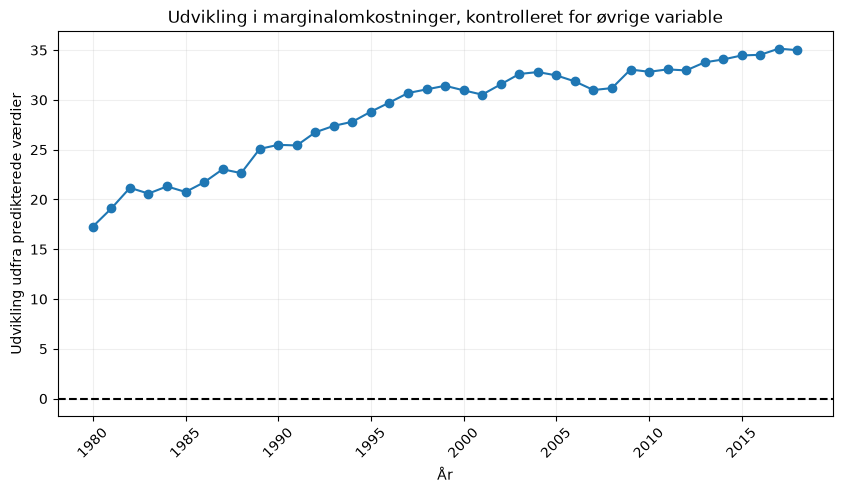

In [ ]:
x = ["const","loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]
X10 = df[x + ["RXR"] + years + xi_m]

df["logmc"] = np.log(df["mc_IV"])

marginalomkostningsfunktionen = mlr.ols(df["logmc"],X10)
df["logmc_hat"] = marginalomkostningsfunktionen["y_hat"].flatten()
df["mc_hat"] = np.exp(df["logmc_hat"])

mlr.output(marginalomkostningsfunktionen)

mcAar = df.groupby("year")["mc_hat"].mean()
plt.figure(figsize=(10, 5))
plt.plot(mcAar.index, mcAar.values, marker="o")
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("År")
plt.ylabel("Udvikling udfra predikterede værdier")
plt.title("Udvikling i marginalomkostninger, kontrolleret for øvrige variable")
plt.xticks(rotation=45)
plt.grid(alpha=0.2)
plt.show()

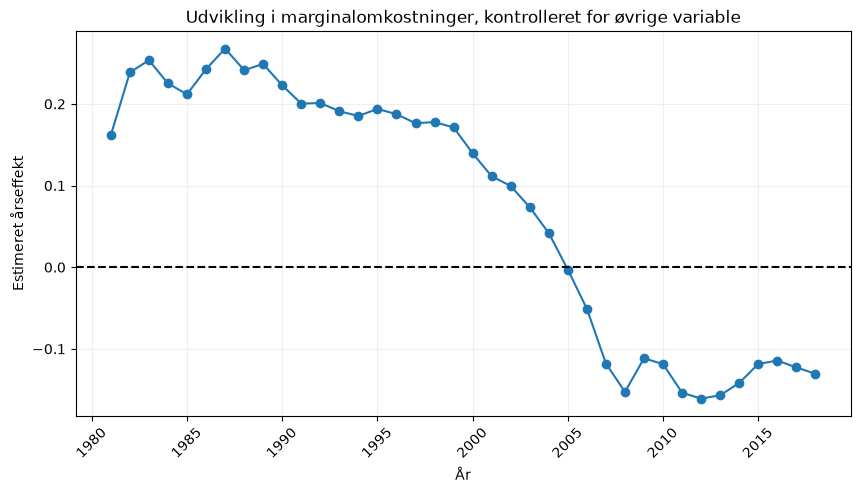

In [ ]:
x = ["const","loghp", "logmpg", "logheight","logfootprint","logweight","lognumber_trims","releaseYear","yearsSinceDesign","sport","EV","truck","suv","van"]

X11 = df[x + ["RXR"] + years + xi_m]

df["logmc"] = np.log(df["mc_IV"])

marginalomkostningsfunktionen = mlr.ols(df["logmc"],X11)
parametre = pd.Series(marginalomkostningsfunktionen["beta_hat"].flatten(),index=marginalomkostningsfunktionen["lbl_X"])
year_effects = parametre[parametre.index.str.startswith("y_")]
yearsForPlot = year_effects.index.str.replace("y_", "").astype(int)

plt.figure(figsize=(10, 5))
plt.plot(yearsForPlot, year_effects.values, marker="o")
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("År")
plt.ylabel("Estimeret årseffekt")
plt.title("Udvikling i marginalomkostninger, kontrolleret for øvrige variable")
plt.xticks(rotation=45)
plt.grid(alpha=0.2)
plt.show()

Opgave 4: 4c

In [ ]:
np.random.seed(1)

def simulate(obs,gamma1,gamma2):
    data = []
    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25
    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)
    for _ in range(obs):
        z = np.random.normal(0,1)
        xi = np.random.normal(0,1)
        v = np.random.normal(0,1)

        u = (v - xi) / (beta1 - gamma1)
        p = eta0 + eta1*z + u
        y = beta0 + beta1*p + xi

        data.append((y,p,z,xi))    
    
    return(data)

def monte_carlo(reps, obs, gamma1, gamma2):
    beta1hats = []
    betaIVhats = []

    for _ in range(reps):
        data = simulate(obs,gamma1,gamma2)        
        dfMonte = pd.DataFrame(data, columns=["y", "p", "z","xi"])
        dfMonte["const"] = 1
        ols = mlr.ols(dfMonte["y"],dfMonte[["const","p"]])
        beta1hat = ols["beta_hat"].flatten()[1]
        beta1hats.append(beta1hat)

        iv = mlr.tsls(dfMonte["y"],dfMonte["const"],dfMonte["p"],dfMonte["z"])
        betaIVhat = iv["beta_hat"].flatten()[1]
        betaIVhats.append(betaIVhat)

    biasOLS = np.mean(beta1hats) - (-0.1)
    biasIV = np.mean(betaIVhats) - (-0.1)

    variansOLS = np.var(beta1hats)
    variansIV = np.var(betaIVhats)

    return {
        "OLS gennemsnit": np.mean(beta1hats),
        "OLS bias": biasOLS,
        "OLS varians": variansOLS,
        "IV gennemsnit": np.mean(betaIVhats),
        "IV bias": biasIV,
        "IV varians": variansIV
    }

In [ ]:
np.random.seed(1)
print(monte_carlo(500,500,1,1))

{'OLS gennemsnit': np.float64(0.2667421626643262), 'OLS bias': np.float64(0.36674216266432624), 'OLS varians': np.float64(0.00056730011456786), 'IV gennemsnit': np.float64(-0.10093253658289707), 'IV bias': np.float64(-0.0009325365828970616), 'IV varians': np.float64(0.00244125729542006)}


In [ ]:
np.random.seed(1)
print(monte_carlo(500,500,1,0.25))

{'OLS gennemsnit': np.float64(0.43293109228155), 'OLS bias': np.float64(0.53293109228155), 'OLS varians': np.float64(0.0005835921356216973), 'IV gennemsnit': np.float64(-0.1377539501413015), 'IV bias': np.float64(-0.03775395014130151), 'IV varians': np.float64(0.060346314225965966)}


In [ ]:
np.random.seed(1)
print(monte_carlo(500,500,0.25,1))

{'OLS gennemsnit': np.float64(0.016690688120467412), 'OLS bias': np.float64(0.11669068812046741), 'OLS varians': np.float64(5.74332760616222e-05), 'IV gennemsnit': np.float64(-0.10029671618546723), 'IV bias': np.float64(-0.00029671618546722733), 'IV varians': np.float64(0.00024715208156112173)}
